<a href="https://colab.research.google.com/github/iwemrn/data_analysis_itmo/blob/main/%D0%9B%D0%A02_%D0%95%D1%80%D0%BE%D1%85%D0%B8%D0%BD%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторная работа №1. Кластерный анализ методом k-means.**
ФИО: Ерохина Софья Алексеевна
Файл: Леденцы

План выполнения работы:

1. Определить оптимальное число кластеров.
2. Выполнить кластеризацию методом K-means.
3. Определить центроиды и численность кластеров.
4. Оценить компактность полученных групп.
5. Визуализировать кластеры и центроиды с помощью PCA.
6. Интерпретировать результаты.
7. Сравнить результаты с иерархической кластеризацией.


В файле "леденцы.pdf" дано описание данных по признакам. Продублирую их в текущем файле:
* V1: Я потребляю леденцы, чтобы освежить дыхание
* V2: Я потребляю леденцы, чтобы чувствовать себя увереннее
* V3: Я потребляю леденцы, чтобы освежить полость рта
* V4: Я потребляю леденцы, чтобы избавиться от неприятного вкуса во рту
* V5: Я потребляю леденцы как заменитель других кондитерских изделий
* V6: Я потребляю леденцы, когда мне хочется чего-нибудь сладкого
* V7: Леденцы помогают мне сконцентрироваться
* V8: Я потребляю леденцы, чтобы отвлечься на несколько минут и подумать
* V9: Я потребляю леденцы для того, чтобы облегчить боль в горле
* V10: Я потребляю леденцы для того, чтобы избавиться от заложенности носа
* V11: Я потребляю леденцы для улучшения самочувствия

---

Первично, можно разделить данные признаки на следующие группы: признаки V1-V4 могут говорить о гигиене и свежести, признаки V5 и V6 - "любовь" к сладостям, признаки V7 и V8 говорят о психологическом комфорте, признаки V9 - V11 - облегчение симптомов болезни.


Для работы подключаем библиотеки:

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import kmeans_plusplus
from sklearn.metrics import pairwise_distances_argmin

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

%matplotlib inline
plt.style.use('ggplot')


Загружаем файл с исходными данными:

In [6]:
drive.mount("/content/drive")

df = pd.read_csv("/content/drive/MyDrive/AD_Python/Леденцы.dat", sep=";")

df.head()

Mounted at /content/drive


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


Далее - посмотрим на структуру данных

In [7]:
print("Размер таблицы:", df.shape)

print("\nТипы данных:")
print(df.dtypes)

print("\nПропущенные значения:")
print(df.isnull().sum())

print("\nОписательная статистика:")
display(df.describe())

Размер таблицы: (338, 11)

Типы данных:
V1     int64
V2     int64
V3     int64
V4     int64
V5     int64
V6     int64
V7     int64
V8     int64
V9     int64
V10    int64
V11    int64
dtype: object

Пропущенные значения:
V1     0
V2     0
V3     0
V4     0
V5     0
V6     0
V7     0
V8     0
V9     0
V10    0
V11    0
dtype: int64

Описательная статистика:


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


При просмотре видим, что шакала оценок варьируется от 2 до 5,количество данных - 338, а среднее и отклонение находятся в диапозоне от 3,20 до 3,60 и от 0,82 до 0,99, соответственно. Это позволяет предположить, что ни один из признаков не будет существенно доминировать при рассчёте расстояний.
Но, для дальнейшего определения наличия или отсутствия однородности респондентов следует исследовать далее.

Говоря об стандартизации - как было помечено ранее, данные варьируются от 2 до 5, и измерены по одной шкале, следовательно, в рамках анализа можно использовать исходные данные без стандартизации

Далее - создадим матрицу признаков для дальнейшей кластеризации

In [10]:

# Каждая строка — респондент.
# Каждый столбец — оценка одного из 11 высказываний.

features = [f'V{i}' for i in range(1, 12)]

X = df[features].copy()

print("Размер матрицы:", X.shape)
display(X.head())


Размер матрицы: (338, 11)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


В рамках текущей работы следует предварительно рассмотреть диаграмму "локтя" для дальнейшего выбора оптимального числа кластеров. Для этого последовательно запускаем для каждого k количества кластеров метод k-means. Задача заключается в том, чтобы выявить число кластеров при наибольшем "скачке" графика - он будет символизировать то, что алгоритм начинает соединять кластеры, которые наиболее удалены друг от друга

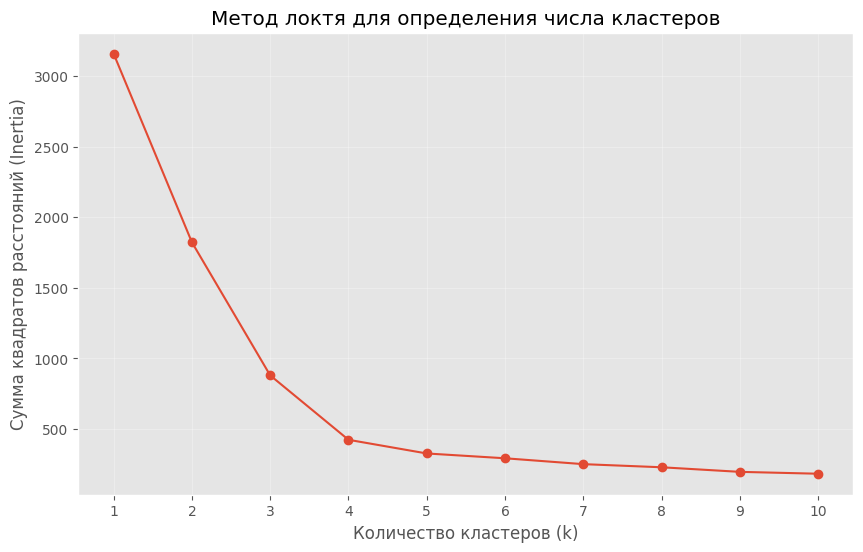

In [11]:

# Проверяем количество кластеров от 1 до 10
K = range(1, 11)

# Список для хранения суммы квадратов расстояний
inertia = []

for k in K:
    model = KMeans(
        n_clusters=k,
        random_state=100,
        max_iter=300,
        n_init=10
    )

    model.fit(df)
    inertia.append(model.inertia_)

# Строим график локтя
plt.figure(figsize=(10, 6))

plt.plot(K, inertia, marker='o')

plt.title('Метод локтя для определения числа кластеров')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Сумма квадратов расстояний (Inertia)')
plt.xticks(list(K))
plt.grid(True, alpha=0.3)

plt.show()


На полученном графике наблюдается значительное уменьшение Inertia (сумма квадратов расстояния центроидов) при увеличении количества кластеров от 1 до 4. После достижения k = 4 снижение суммы квадратов становится значительно менее выраженным, и кривая приобретает более пологий характер.
Предварительно - возьмём в качестве оптимального числа кластеров 4

Теперь рассчитаем значение для разного числа кластеров и посмотрим, при каком k разделение наиболее качественное, используя коэффициент силуэта (число от -1 до 1, которое показывает, насколько хорошо каждая точка соответствует своему кластеру)

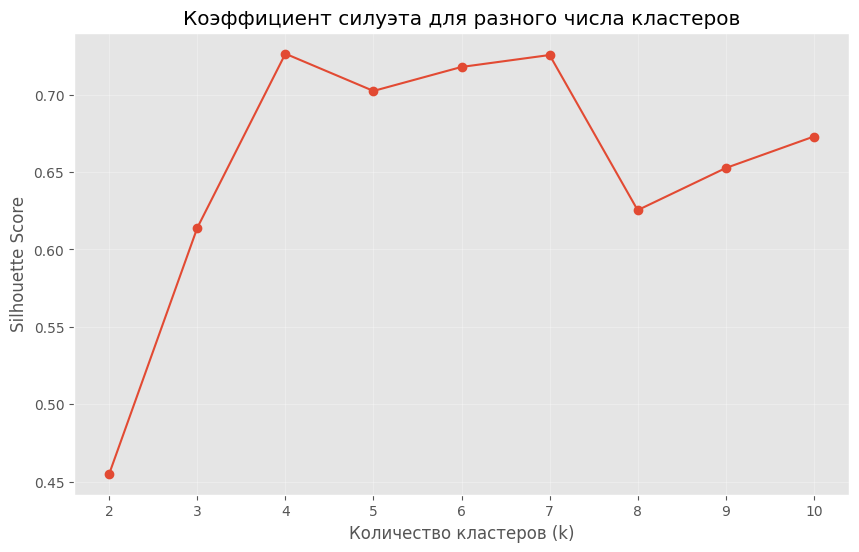

k = 2: Silhouette Score = 0.455
k = 3: Silhouette Score = 0.614
k = 4: Silhouette Score = 0.727
k = 5: Silhouette Score = 0.702
k = 6: Silhouette Score = 0.718
k = 7: Silhouette Score = 0.726
k = 8: Silhouette Score = 0.625
k = 9: Silhouette Score = 0.653
k = 10: Silhouette Score = 0.673


In [17]:

# Проверяем качество кластеризации для k от 2 до 10
K = range(2, 11)
silhouette_scores = []

for k in K:
    model = KMeans(
        n_clusters=k,
        random_state=100,
        max_iter=300,
        n_init=10
    )

    labels = model.fit_predict(X)

    score = silhouette_score(X, labels)
    silhouette_scores.append(score)

# Строим график коэффициента силуэта
plt.figure(figsize=(10, 6))

plt.plot(
    K,
    silhouette_scores,
    marker='o'
)

plt.title('Коэффициент силуэта для разного числа кластеров')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Silhouette Score')
plt.xticks(list(K))
plt.grid(True, alpha=0.3)

plt.show()

# Выводим значения
for k, score in zip(K, silhouette_scores):
    print(f'k = {k}: Silhouette Score = {score:.3f}')


При исследовании графика зависимости количества кластеров и рассчитанных для них коэффициентов видим, что при k=4 коэффициент силуэта стремится к 1.
Оба метода согласованно указывают на целесообразность выделения четырёх кластеров. Для дальнейшего анализа методом K-means выбрано значение k = 4.

Далее - обучение модели k-means

In [18]:

# Создаём модель K-means с четырьмя кластерами
kmeans = KMeans(
    n_clusters=4,
    random_state=100,
    max_iter=300,
    n_init=10
)

# Обучаем модель и получаем номера кластеров
clusters = kmeans.fit_predict(X)

# Основные характеристики модели
print("Количество кластеров:", kmeans.n_clusters)
print("Количество итераций:", kmeans.n_iter_)
print("Inertia:", round(kmeans.inertia_, 2))

# Численность кластеров
print("\nРазмеры кластеров:")
print(pd.Series(clusters).value_counts().sort_index())


Количество кластеров: 4
Количество итераций: 2
Inertia: 423.14

Размеры кластеров:
0    108
1    110
2     61
3     59
Name: count, dtype: int64


Здесь можно увидеть, как размеры кластеров при использовании данного метода совпадают с размерами из предыдущей лабораторной работы.
Для визуализации работы будем использовать циклическую генерацию диаграммы, в которой будет видно каждый этап k-means, с назначениями центроидов и расчётом расстояний

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


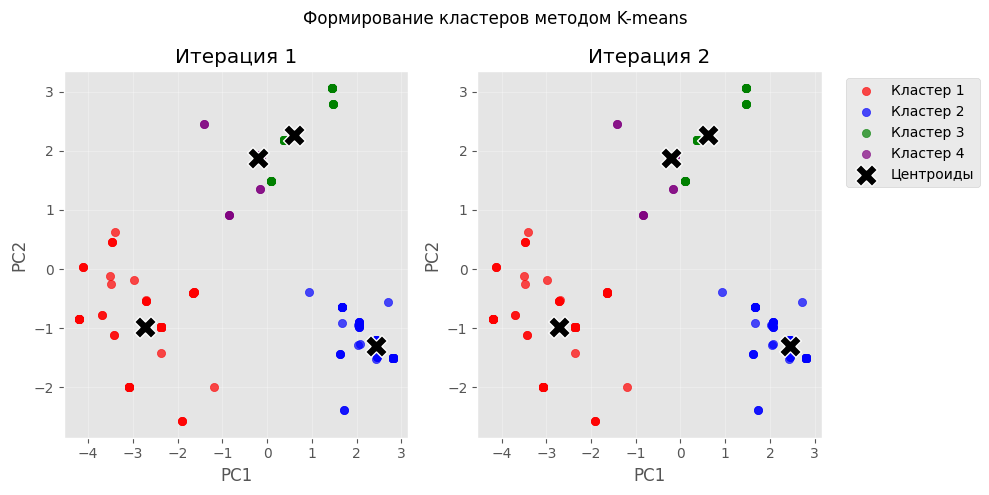

Количество итераций: 2


In [20]:

# Понижение размерности только для визуализации
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Начальные центроиды по методу k-means++
centers, _ = kmeans_plusplus(
    X.to_numpy(),
    n_clusters=4,
    random_state=100
)

history = []

# Итеративное формирование кластеров
for iteration in range(20):

    # Назначаем объекты ближайшим центроидам
    labels = pairwise_distances_argmin(X, centers)

    # Пересчитываем координаты центроидов
    new_centers = np.array([
        X.to_numpy()[labels == i].mean(axis=0)
        if np.any(labels == i) else centers[i]
        for i in range(4)
    ])

    # Сохраняем состояние текущей итерации
    history.append((labels.copy(), new_centers.copy()))

    # Проверяем сходимость
    if np.allclose(centers, new_centers):
        break

    centers = new_centers

# Показываем первые три итерации и итоговую
steps = sorted(set(
    list(range(min(3, len(history)))) + [len(history) - 1]
))

fig, axes = plt.subplots(
    1, len(steps),
    figsize=(5 * len(steps), 5),
    squeeze=False
)

colors = ['red', 'blue', 'green', 'purple']

for ax, step in zip(axes[0], steps):
    labels, centers = history[step]

    # Переносим центроиды в то же пространство PCA
    centers_pca = pca.transform(centers)

    # Рисуем все четыре кластера
    for i in range(4):
        ax.scatter(
            X_pca[labels == i, 0],
            X_pca[labels == i, 1],
            c=colors[i],
            label=f'Кластер {i + 1}',
            s=35,
            alpha=0.7
        )

    # Чёрные крестики — центроиды
    ax.scatter(
        centers_pca[:, 0],
        centers_pca[:, 1],
        c='black',
        marker='X',
        s=250,
        edgecolors='white',
        linewidths=1,
        label='Центроиды',
        zorder=10
    )

    ax.set_title(f'Итерация {step + 1}')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.grid(True, alpha=0.3)

axes[0, -1].legend(bbox_to_anchor=(1.05, 1))
plt.suptitle('Формирование кластеров методом K-means')
plt.tight_layout()
plt.show()

print(f'Количество итераций: {len(history)}')


На графике видим, что возможно выделить 3 кластера - протестируем это ниже

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


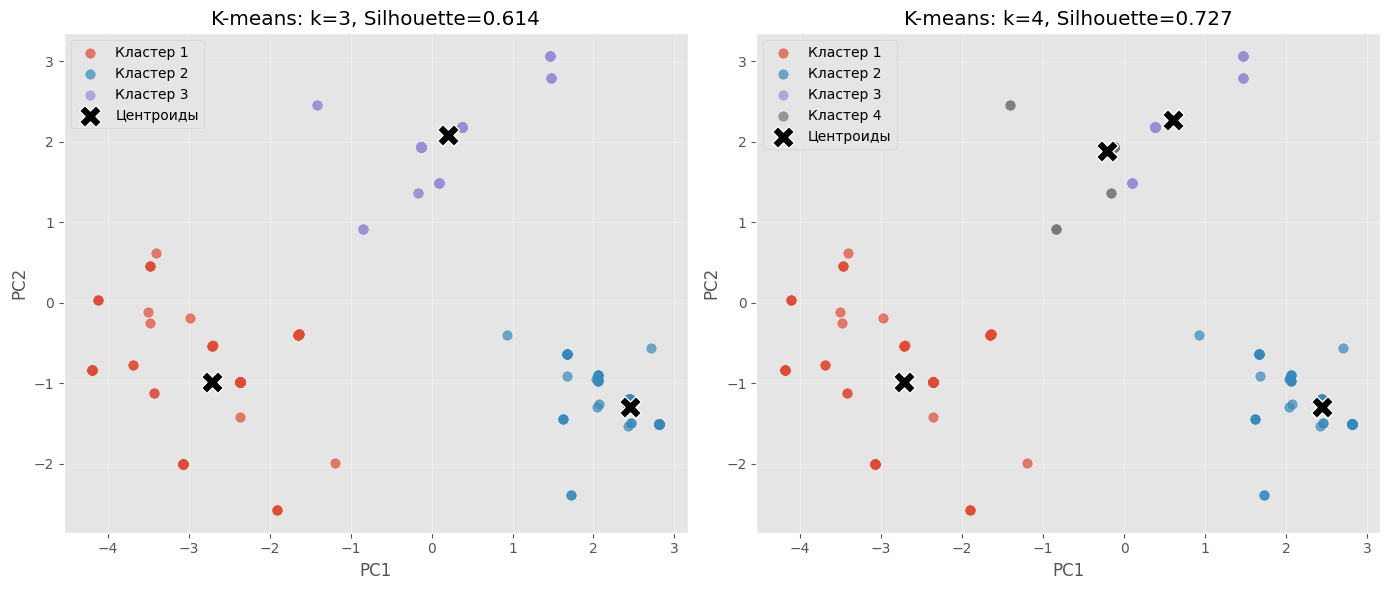

In [21]:

# Сравнение K-means при k=3 и k=4

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, k in zip(axes, [3, 4]):
    model = KMeans(
        n_clusters=k,
        random_state=100,
        n_init=10
    )

    labels = model.fit_predict(X)
    centers_pca = pca.transform(model.cluster_centers_)

    for i in range(k):
        ax.scatter(
            X_pca[labels == i, 0],
            X_pca[labels == i, 1],
            s=45,
            alpha=0.7,
            label=f'Кластер {i + 1}'
        )

    ax.scatter(
        centers_pca[:, 0],
        centers_pca[:, 1],
        c='black',
        marker='X',
        s=250,
        edgecolors='white',
        linewidths=1,
        zorder=10,
        label='Центроиды'
    )

    score = silhouette_score(X, labels)

    ax.set_title(f'K-means: k={k}, Silhouette={score:.3f}')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Проанализируем полученные результаты, начнём с графика с тремя кластерами.
Красный кластер достаточно отчётливо выделяется слева. Фиолетовый кластер располагается в правой нижней части. Синий кластер имеет более сложную структуру: часть объектов находится ближе к центру, а остальные — заметно выше.
В результате синий кластер охватывает две визуально различимые группы наблюдений.Следовательно, при переходе от трёх к четырём кластерам алгоритм разделяет неоднородную группу на **два более компактных** сегмента.

In [22]:

# Итоговая модель K-means
kmeans = KMeans(
    n_clusters=4,
    random_state=100,
    max_iter=300,
    n_init=10
)

clusters = kmeans.fit_predict(X)

# Центроиды в исходном пространстве 11 признаков
centroids = kmeans.cluster_centers_

print("Число кластеров:", kmeans.n_clusters)
print("Количество итераций:", kmeans.n_iter_)
print("Inertia:", round(kmeans.inertia_, 2))


Число кластеров: 4
Количество итераций: 2
Inertia: 423.14


In [23]:

# Евклидовы расстояния до центроидов своих кластеров
distances = np.linalg.norm(
    X.to_numpy() - centroids[clusters],
    axis=1
)

# Таблица результатов
cluster_distances = pd.DataFrame({
    'Cluster': clusters,
    'Distance': distances
})

# Среднее расстояние и численность по каждому кластеру
cluster_stats = cluster_distances.groupby('Cluster').agg(
    Количество=('Distance', 'size'),
    Среднее_расстояние=('Distance', 'mean')
)

# Для всей выборки
print("Общее среднее расстояние:",
      round(distances.mean(), 3))

print("\nКомпактность кластеров:")
display(cluster_stats.round(3))


Общее среднее расстояние: 0.934

Компактность кластеров:


,Количество,Среднее_расстояние
Cluster,,
0,108,1.385
1,110,0.849
2,61,0.830
3,59,0.375


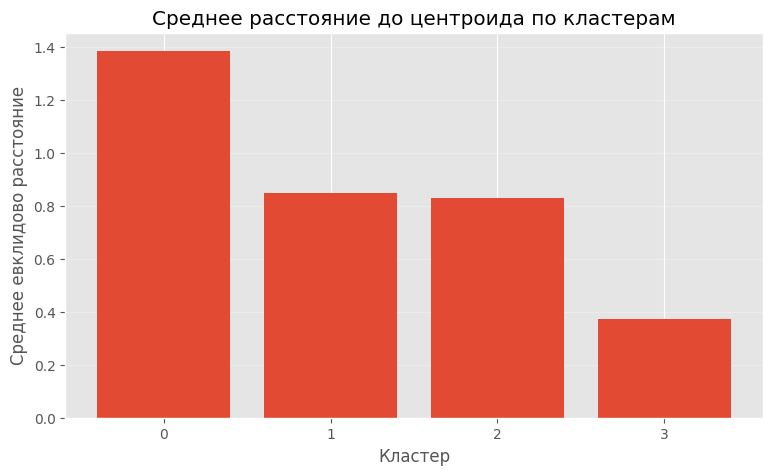

In [24]:

plt.figure(figsize=(9, 5))

plt.bar(
    cluster_stats.index.astype(str),
    cluster_stats['Среднее_расстояние']
)

plt.title('Среднее расстояние до центроида по кластерам')
plt.xlabel('Кластер')
plt.ylabel('Среднее евклидово расстояние')

plt.grid(axis='y', alpha=0.3)
plt.show()


После выполнения кластеризации методом K-means была проведена оценка компактности выделенных групп. Для этого рассчитано среднее евклидово расстояние от каждого наблюдения до центроида соответствующего кластера в исходном пространстве 11 признаков.

Модель сформировала четыре кластера за две итерации. Значение внутрикластерной суммы квадратов расстояний (Inertia) составило 423,14.

Наибольшее среднее расстояние до центроида наблюдается в кластере 0 — приблизительно 1,38. Это свидетельствует о сравнительно большом разбросе оценок среди респондентов данной группы.

Кластеры 1 и 2 характеризуются близкими значениями средних расстояний — около 0,85 и 0,83 соответственно, что указывает на сопоставимую компактность этих групп.

Наиболее компактным является кластер 3, для которого среднее евклидово расстояние составляет приблизительно 0,37. Это свидетельствует о высокой степени сходства ответов респондентов внутри данного кластера.

Построим итоговый scatterplot с отображёнными центроидами

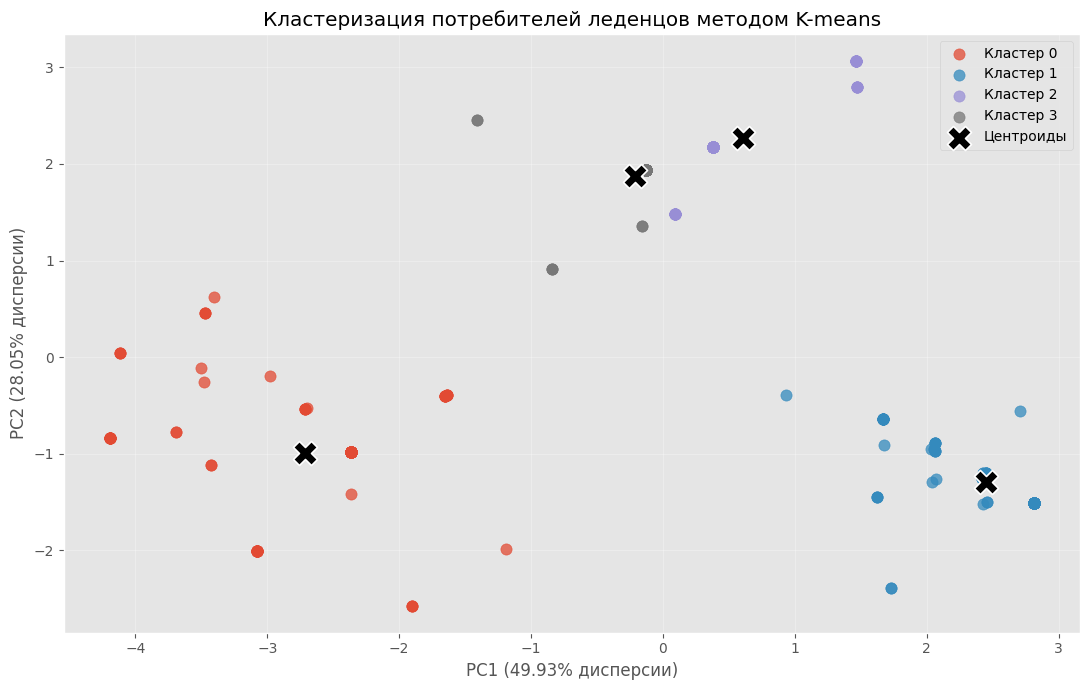

Суммарная объяснённая дисперсия: 77.98%


In [25]:

# Понижение размерности для визуализации
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

# Преобразуем центроиды тем же PCA
centroids_pca = pca.transform(
    pd.DataFrame(centroids, columns=X.columns)
)

# Доля объяснённой дисперсии
variance = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(11, 7))

# Строим кластеры циклом
for i in range(4):
    plt.scatter(
        X_pca[clusters == i, 0],
        X_pca[clusters == i, 1],
        s=65,
        alpha=0.75,
        label=f'Кластер {i}'
    )

# Центроиды — чёрные крестики
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    c='black',
    marker='X',
    s=300,
    edgecolors='white',
    linewidths=1.2,
    label='Центроиды',
    zorder=10
)

plt.title('Кластеризация потребителей леденцов методом K-means')
plt.xlabel(f'PC1 ({variance[0]:.2f}% дисперсии)')
plt.ylabel(f'PC2 ({variance[1]:.2f}% дисперсии)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

print(f'Суммарная объяснённая дисперсия: {variance.sum():.2f}%')


Первая главная компонента объясняет 49,93% дисперсии данных, вторая — 28,05%. Суммарная объяснённая дисперсия составляет 77,98%.

На диаграмме рассеяния выделены четыре кластера, представленные различными цветами. Центроиды отображены чёрными крестиками и характеризуют среднее положение объектов соответствующих групп.

По результатам визуального анализа установлено, что кластеры имеют достаточно чёткие пространственные границы в двумерной проекции. Это согласуется с ранее рассчитанным коэффициентом силуэта 0,727 и подтверждает хорошую различимость полученных групп.

In [26]:

# Координаты центроидов по исходным 11 признакам
centroid_df = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=X.columns
)

centroid_df.index.name = 'Cluster'

print("Средние значения признаков по кластерам:")
display(centroid_df.round(2))


Средние значения признаков по кластерам:


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
Cluster,,,,,,,,,,,
0,2.82,2.83,2.77,2.62,2.61,2.58,2.75,2.92,4.95,4.81,4.86
1,4.85,4.80,4.84,4.68,3.04,3.04,3.00,2.99,3.07,3.05,3.05
2,3.00,3.00,3.00,3.00,4.85,4.85,3.00,2.92,2.75,2.75,2.75
3,3.00,2.97,2.97,2.92,2.92,2.95,4.92,4.92,3.00,3.00,3.00


**Вывод:**
## Вывод

В ходе лабораторной работы был проведён иерархический кластерный анализ потребителей леденцов на основе данных опроса 338 респондентов по 11 признакам, характеризующим основные мотивы потребления продукции.

На этапе предварительной обработки были изучены структура данных и описательная статистика. Установлено, что пропущенные значения отсутствуют, а признаки имеют сопоставимые масштабы измерения, поэтому кластеризация проводилась без дополнительной стандартизации.

Для выполнения кластерного анализа был выбран метод Варда с использованием евклидовой метрики расстояния. На основании построенной дендрограммы и анализа расстояний между последовательными объединениями было обосновано выделение **четырёх кластеров**. Наибольший скачок расстояния наблюдался между значениями 13,03 и 30,22, что позволило выбрать пороговое расстояние 17.

В результате анализа были выделены четыре группы потребителей:

1. **Оздоровительные потребители (108 человек, 31,95%)**
2. **Потребители, ориентированные на свежесть (110 человек, 32,54%)**
3. **Любители сладкого (61 человек, 18,05%)**
4. **Потребители, ориентированные на концентрацию и отдых (59 человек, 17,46%)**

Содержательная интерпретация кластеров была выполнена на основании средних значений признаков внутри каждой группы. Построенная тепловая карта наглядно продемонстрировала различия в потребностях выделенных сегментов.

Дополнительно было проведено сравнение трёх методов иерархической кластеризации: Уорда (Ward), полной связи (Complete) и средней связи (Average). Все методы показали одинаковое значение коэффициента силуэта — **0,727**, что свидетельствует о хорошем качестве разделения наблюдений. В качестве основного был сохранён метод Уорда, поскольку он позволил получить чётко интерпретируемые группы потребителей.
